# EMQA_L3_halflife

**Decay of a volatility shock, 100(alpha+beta)^h, implied by GARCH(1,1)-t models for the Romanian base price (percent and EUR/MWh shocks, 2019-01-01 to 2026-10-31), Brent crude oil (ICE Brent front month, from 2019), EU carbon allowances (SparkChange EUA ETC, from 2021-10-19) and OMV Petrom shares (BVB: SNP, from 2019), all to the cut-off; half-lives in brackets: oil and carbon shocks fade in weeks, not days.**

Energy Markets Quantitative Analysis (EMQA), Lecture 3 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L3/EMQA_L3_halflife/EMQA_L3_halflife.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
C_PCT, C_EUR = PAL['RO'], PAL['c7']          # percent changes, EUR/MWh changes


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    # legend centred under the axes, outside the plotting area
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def slide(label, key, x, k=None):
    # prints a number shown on the slide; [key] = its name in lectures/L3/L3_numbers.json
    if k is not None:
        x = round(float(x), k)
    print(f'{label:<58s} {x}   [{key}]')

## Half-life of a volatility shock

$\mathrm{E}_t[\sigma^2_{t+h}]-\bar\sigma^2=(\alpha+\beta)^{h-1}(\sigma^2_{t+1}-\bar\sigma^2)$, so half of the shock is gone after $h_{1/2}=\ln 0.5/\ln(\alpha+\beta)$ days. GARCH(1,1)-t on each series, over its own sample. Markets: log returns on trading days; Brent without the monthly roll days; OMV Petrom without zero-volume days.

In [3]:
# Romanian daily base price (mean of all MTUs of the CET/CEST delivery day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month; panel from 2019-01-01, on the full calendar
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp('2019-01-01')
CAL = pd.date_range(START, END, freq='D')
P = PD['RO'].reindex(CAL)
print('Romania, daily base price:', START.date(), 'to', END.date(), '|', len(CAL), 'days, missing:', int(P.isna().sum()))

Romania, daily base price: 2019-01-01 to 2026-10-31 | 2861 days, missing: 0


In [4]:
# daily changes on the full calendar: percent (log) and EUR/MWh
r = 100 * np.log(P.where(P > 0)).diff()      # r_t = 100 ln(P_t / P_{t-1}); missing if a price is <= 0
u = P.diff()                                  # Delta P_t = P_t - P_{t-1}, EUR/MWh

In [5]:
import statsmodels.api as sm


def mean_design(y, lags=7):
    # constant + AR(1..7) + six day-of-week dummies (Monday = base)
    X = pd.DataFrame({f'L{k}': y.shift(k) for k in range(1, lags + 1)}, index=y.index)
    for j in range(1, 7):
        X[f'D{j}'] = (y.index.dayofweek == j).astype(float)
    X.insert(0, 'const', 1.0)
    return X


def mean_fit(y, lags=7):
    # OLS mean equation; returns (residuals = shocks, fitted model)
    X = mean_design(y, lags)
    df = pd.concat([y.rename('y'), X], axis=1).dropna()
    m = sm.OLS(df['y'], df.drop(columns='y')).fit()
    return m.resid, m


E_PCT, M_PCT = mean_fit(r)       # shocks epsilon_t, percent
E_EUR, M_EUR = mean_fit(u)       # shocks u_t, EUR/MWh
print('shocks:', E_PCT.index[0].date(), 'to', E_PCT.index[-1].date(), '|', len(E_PCT), 'days')

shocks: 2019-01-09 to 2026-10-31 | 2853 days


In [6]:
try:
    import arch
except ImportError:          # Google Colab: install the arch package once
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'arch'])
from arch import arch_model


def fit(e, vol='GARCH', o=0, dist='t'):
    # zero-mean GARCH(1,1) (o=0) or GJR-GARCH(1,1,1) (o=1), Student-t shocks by default
    return arch_model(np.asarray(e, float), mean='Zero', vol=vol, p=1, o=o, q=1, dist=dist,
                      rescale=False).fit(disp='off', show_warning=False)

In [7]:
def mkt_returns(px, drop_roll=False, vol=None):
    # 100 x log returns on trading days; drop_roll removes the first trading day of each month (futures roll);
    # vol: keep only days with a positive traded volume
    px = px.dropna()
    if vol is not None:
        px = px[vol.reindex(px.index).fillna(0) > 0]
    r_ = 100 * np.log(px).diff().dropna()
    if drop_roll:
        first = r_.index.to_series().groupby(r_.index.to_period('M')).transform('min') == r_.index
        r_ = r_[~first]
    return r_


FU = pd.read_csv(DATA + 'fuels_daily.csv', usecols=['date', 'brent_usd_bbl'], parse_dates=['date']).set_index('date')
BRENT = mkt_returns(FU['brent_usd_bbl'].loc[str(START - pd.Timedelta(days=10)):str(END)], drop_roll=True).loc[START:END]
print('Brent BZ=F returns:', BRENT.index[0].date(), 'to', BRENT.index[-1].date(), '|', len(BRENT), 'trading days (roll days dropped)')

Brent BZ=F returns: 2019-01-03 to 2026-10-30 | 1878 trading days (roll days dropped)


In [8]:
EUA = pd.read_csv(DATA + 'eua_daily.csv', usecols=['date', 'eua_etc_co2l_eur_per_unit'], parse_dates=['date']).set_index('date')['eua_etc_co2l_eur_per_unit']
EUAR = mkt_returns(EUA.loc[:str(END)])
EQ = pd.read_csv(DATA + 'ro_energy_equities_daily.csv', usecols=['date', 'SNP_adjclose_ron', 'SNP_volume'], parse_dates=['date']).set_index('date')
SNP = mkt_returns(EQ['SNP_adjclose_ron'].loc[str(START - pd.Timedelta(days=10)):str(END)], vol=EQ['SNP_volume']).loc[START:END]
print('EUA:', EUAR.index[0].date(), 'to', EUAR.index[-1].date(), '| SNP:', SNP.index[0].date(), 'to', SNP.index[-1].date())

EUA: 2021-10-19 to 2026-10-30 | SNP: 2019-01-03 to 2026-10-30


### Numbers on the slide

In [9]:
XM = {'RO_pct': E_PCT, 'RO_eur': E_EUR, 'BRENT': BRENT - BRENT.mean(), 'EUA': EUAR - EUAR.mean(), 'SNP': SNP - SNP.mean()}
PERS, HL = {}, {}
for k, e in XM.items():
    p = fit(e.dropna()).params
    PERS[k] = round(float(p['alpha[1]'] + p['beta[1]']), 4)
    HL[k] = round(float(np.log(0.5) / np.log(p['alpha[1]'] + p['beta[1]'])), 1)     # half-life, days
    slide(f'{k}: alpha + beta', f'xm.{k}.pers', PERS[k])
    slide(f'{k}: half-life, days', f'xm.{k}.hl', HL[k])
slide('Brent half-life, weeks (5 trading days)', 'xm.BRENT.hl_weeks', HL['BRENT'] / 5, 1)
slide('EUA half-life, weeks (5 trading days)', 'xm.EUA.hl_weeks', HL['EUA'] / 5, 1)

RO_pct: alpha + beta                                       0.7459   [xm.RO_pct.pers]
RO_pct: half-life, days                                    2.4   [xm.RO_pct.hl]
RO_eur: alpha + beta                                       0.9939   [xm.RO_eur.pers]
RO_eur: half-life, days                                    113.5   [xm.RO_eur.hl]
BRENT: alpha + beta                                        0.9732   [xm.BRENT.pers]
BRENT: half-life, days                                     25.6   [xm.BRENT.hl]
EUA: alpha + beta                                          0.9917   [xm.EUA.pers]
EUA: half-life, days                                       82.8   [xm.EUA.hl]
SNP: alpha + beta                                          0.9342   [xm.SNP.pers]
SNP: half-life, days                                       10.2   [xm.SNP.hl]
Brent half-life, weeks (5 trading days)                    5.1   [xm.BRENT.hl_weeks]
EUA half-life, weeks (5 trading days)                      16.6   [xm.EUA.hl_weeks]


### Chart

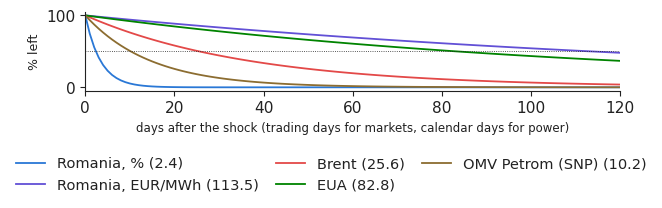

In [10]:
fig, ax = plt.subplots(figsize=(6.4, 2.1))
hh = np.arange(0, 121)
for k, lab, c in [('RO_pct', 'Romania, %', C_PCT), ('RO_eur', 'Romania, EUR/MWh', C_EUR), ('BRENT', 'Brent', PAL['c8']),
                  ('EUA', 'EUA', PAL['c6']), ('SNP', 'OMV Petrom (SNP)', '#8c6d31')]:
    ax.plot(hh, 100 * PERS[k] ** hh, color=c, lw=1.3, label=f'{lab} ({HL[k]})')
ax.axhline(50, color='#222222', lw=0.6, ls=':')
ax.set_xlabel('days after the shock (trading days for markets, calendar days for power)', fontsize=8.5)
ax.set_ylabel('% left', fontsize=9)
ax.set_xlim(0, 120)
legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.26, 1, 1))
plt.savefig('halflife.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()